<a href="https://colab.research.google.com/github/Dalton115/MAT-422/blob/main/HW3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW3.2    3.3.1 - 3.3.3

* Used Gemini as a study aid and coding partner to clarify multivariate calculus definitions, debug python code, and format LaTex formulas.
__________________________________________________________________

1. Necessary and sufficient conditions of local minimizers (3.3.1)
2. Convexity and global minimizers (3.3.2)
3. Gradient descent (3.3.3)

__________________________________________________________________

# Necessary and sufficient conditions of local minimizers (3.3.1)

Key Concepts (Explained and given python example)

* Global vs. Local Minimizer: A point $x^* \in \mathbb{R}^d$ is a global minimizer if $f(x) \ge f(x^*)$ for all $x \in \mathbb{R}^d$. It is a local minimizer if $f(x) \ge f(x^*)$ within a neighborhood $B_\delta(x^*) \setminus \{x^*\}$.
* Descent Directions: A vector $v$ is a descent direction at $x_0$ if $f(x_0 + \alpha v) < f(x_0)$ for all small $\alpha > 0$. If $f$ is $C^1$, $v$ is a descent direction if $\nabla f(x_0)^T v < 0$. If $\nabla f(x_0) \neq 0$, $v = -\nabla f(x_0)$ is always a descent direction.
* First-Order Necessary Condition (FONC): If $x_0$ is a local minimizer of a continuously differentiable function $f$, then $\nabla f(x_0) = 0$ ($x_0$ is a stationary point).
* Second-Order Sufficient Condition (SOSC): If $x_0$ is a local minimizer of a $C^2$ function $f$, then its Hessian matrix $H_f(x_0)$ is positive semi-definite (PSD), meaning $z^T H_f(x_0) z \ge 0$ for all $z \in \mathbb{R}^d$.


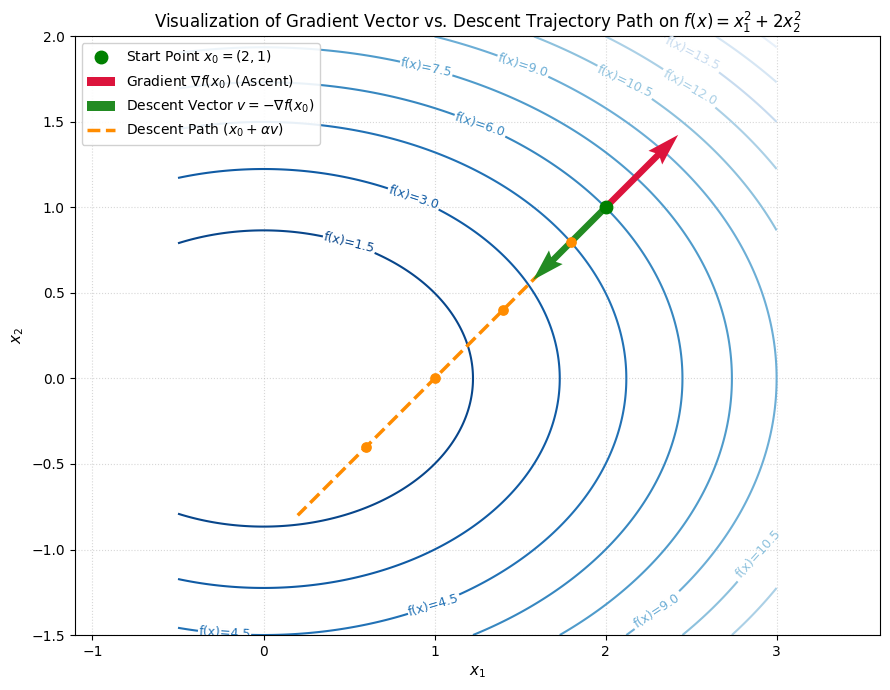

=== NUMERICAL VERIFICATION ===
Point x0: [2. 1.]
f(x0): 6.0000
Gradient at x0: [4. 4.]
Descent Direction v = -grad_f(x0): [-4. -4.]
Directional Derivative (grad_f(x0)^T * v): -32.0000
Is directional derivative < 0? True

Verifying f(x0 + alpha * v) < f(x0) for small step sizes alpha:
  alpha = 0.05 | x_new = [1.80, 0.80] | f(x_new) = 4.5200 < f(x0) (6.0000) -> True
  alpha = 0.10 | x_new = [1.60, 0.60] | f(x_new) = 3.2800 < f(x0) (6.0000) -> True
  alpha = 0.15 | x_new = [1.40, 0.40] | f(x_new) = 2.2800 < f(x0) (6.0000) -> True
  alpha = 0.20 | x_new = [1.20, 0.20] | f(x_new) = 1.5200 < f(x0) (6.0000) -> True
  alpha = 0.25 | x_new = [1.00, 0.00] | f(x_new) = 1.0000 < f(x0) (6.0000) -> True


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Objective function f(x) = x1^2 + 2*x2^2 and its gradient
def f(x1, x2):
    return x1**2 + 2 * x2**2

def grad_f(x):
    return np.array([2 * x[0], 4 * x[1]])

# 2. Base point x0 and steepest descent direction v
x0 = np.array([2.0, 1.0])
f_x0 = f(x0[0], x0[1])
g0 = grad_f(x0)
v_descent = -g0

# ==========================================
# PART 1: VISUALIZATION
# ==========================================
x1_vals = np.linspace(-0.5, 3.0, 400)
x2_vals = np.linspace(-1.5, 2.0, 400)
X1, X2 = np.meshgrid(x1_vals, x2_vals)
Z = f(X1, X2)

plt.figure(figsize=(9, 7))

# Contour lines with level labels
contours = plt.contour(X1, X2, Z, levels=15, cmap='Blues_r')
plt.clabel(contours, inline=True, fontsize=9, fmt='f(x)=%.1f')

# Starting point x0
plt.plot(x0[0], x0[1], 'go', markersize=9, zorder=6, label=r'Start Point $x_0 = (2, 1)$')

# Unit directional vectors for clean visualization at x0
v_unit = v_descent / np.linalg.norm(v_descent)
g_unit = g0 / np.linalg.norm(g0)
arrow_length = 0.6

# Gradient (Ascent) Vector - Red
plt.quiver(x0[0], x0[1], g_unit[0] * arrow_length, g_unit[1] * arrow_length,
           angles='xy', scale_units='xy', scale=1,
           color='crimson', width=0.008, zorder=5, label=r'Gradient $\nabla f(x_0)$ (Ascent)')

# Descent Vector - Green
plt.quiver(x0[0], x0[1], v_unit[0] * arrow_length, v_unit[1] * arrow_length,
           angles='xy', scale_units='xy', scale=1,
           color='forestgreen', width=0.008, zorder=5, label=r'Descent Vector $v = -\nabla f(x_0)$')

# Descent Path Trajectory Line - Orange Dashed
alphas = np.linspace(0, 0.45, 100)
path = np.array([x0 + a * v_descent for a in alphas])
plt.plot(path[:, 0], path[:, 1], color='darkorange', linestyle='--', linewidth=2.5, zorder=4,
         label=r'Descent Path ($x_0 + \alpha v$)')

# Sample evaluation points along the trajectory
sample_alphas = [0.05, 0.15, 0.25, 0.35]
sample_pts = np.array([x0 + a * v_descent for a in sample_alphas])
plt.scatter(sample_pts[:, 0], sample_pts[:, 1], color='darkorange', s=45, zorder=5)

plt.xlabel(r'$x_1$', fontsize=11)
plt.ylabel(r'$x_2$', fontsize=11)
plt.title(r'Visualization of Gradient Vector vs. Descent Trajectory Path on $f(x) = x_1^2 + 2x_2^2$', fontsize=12)
plt.legend(loc='upper left', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

# ==========================================
# PART 2: NUMERICAL VERIFICATION
# ==========================================
directional_derivative = np.dot(g0, v_descent)

print("=== NUMERICAL VERIFICATION ===")
print(f"Point x0: {x0}")
print(f"f(x0): {f_x0:.4f}")
print(f"Gradient at x0: {g0}")
print(f"Descent Direction v = -grad_f(x0): {v_descent}")
print(f"Directional Derivative (grad_f(x0)^T * v): {directional_derivative:.4f}")
print(f"Is directional derivative < 0? {directional_derivative < 0}\n")

alpha_test_values = [0.05, 0.10, 0.15, 0.20, 0.25]
print("Verifying f(x0 + alpha * v) < f(x0) for small step sizes alpha:")
for alpha in alpha_test_values:
    x_new = x0 + alpha * v_descent
    f_new = f(x_new[0], x_new[1])
    is_decreased = f_new < f_x0
    print(f"  alpha = {alpha:.2f} | x_new = [{x_new[0]:.2f}, {x_new[1]:.2f}] | f(x_new) = {f_new:.4f} < f(x0) ({f_x0:.4f}) -> {is_decreased}")

Visually show and mathematically verify the gradient descent vector (red) and the descent vector (green) which point in opposite directions. Also shows the descent path.

In [1]:
# General imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# Set seed for reproducibility
np.random.seed(42)

# Define f(x) = x^3 and its derivatives
def f_cubic(x):
    return x**3

def df_cubic(x):
    return 3 * x**2

def d2f_cubic(x):
    return 6 * x

x_candidate = 0.0
grad_val = df_cubic(x_candidate)
hess_val = d2f_cubic(x_candidate)

print(f"At x = {x_candidate}:")
print(f"  First Derivative  f'(0)  = {grad_val}")
print(f"  Second Derivative f''(0) = {hess_val} (PSD condition f''(x) >= 0 holds)")

# Test neighborhood points B_delta(0)
delta = 0.1
left_neighbor = x_candidate - delta
right_neighbor = x_candidate + delta

print(f"  f({left_neighbor}) = {f_cubic(left_neighbor)} < f(0) = {f_cubic(x_candidate)}")
print(f"  Is x = 0 a local minimizer? {f_cubic(left_neighbor) >= f_cubic(x_candidate)}")



At x = 0.0:
  First Derivative  f'(0)  = 0.0
  Second Derivative f''(0) = 0.0 (PSD condition f''(x) >= 0 holds)
  f(-0.1) = -0.0010000000000000002 < f(0) = 0.0
  Is x = 0 a local minimizer? False


Show by counter examples that SONC is not sufficient, verifying that $f'(0) = 0$ and $f''(0) \ge 0$ (PSD), yet $x = 0$ is not a local minimizer. f(-.01) < f(0), so x = 0 is not a local minimizer.

In [2]:
# Objective function, gradient, and Hessian
def f_2d(x):
    return x[0]**2 + 3*x[1]**2 - 2*x[0]*x[1] + x[0]

def grad_f_2d(x):
    return np.array([2*x[0] - 2*x[1] + 1.0, 6*x[1] - 2*x[0]])

def hessian_f_2d(x):
    return np.array([[2.0, -2.0],
                     [-2.0, 6.0]])

# Solve FONC: grad f(x*) = 0  =>  A x* = b
A_sys = np.array([[2.0, -2.0], [-2.0, 6.0]])
b_sys = np.array([-1.0, 0.0])
x_star = np.linalg.solve(A_sys, b_sys)

# Verify SOSC: Check if Hessian at x* is Positive Definite
H_at_star = hessian_f_2d(x_star)
eigenvalues = np.linalg.eigvals(H_at_star)

print(f"Stationary Point x*: {x_star}")
print(f"Gradient at x*: {grad_f_2d(x_star)}")
print(f"Hessian Eigenvalues: {eigenvalues}")
print(f"Is Hessian Positive Definite? {np.all(eigenvalues > 0)}")
print("Conclusion: SOSC holds, confirming x* is a strict local minimizer.")

Stationary Point x*: [-0.75 -0.25]
Gradient at x*: [0. 0.]
Hessian Eigenvalues: [1.17157288 6.82842712]
Is Hessian Positive Definite? True
Conclusion: SOSC holds, confirming x* is a strict local minimizer.


Here we verify FONC and SOSC on a 2D function. All of the concepts hold up to the math calculated by np.linalg

# Convexity and global minimizers (3.3.2)
* Convex Sets & Functions: A set $D \subseteq \mathbb{R}^d$ is convex if $(1-\alpha)x + \alpha y \in D$ for all $x,y \in D$ and $\alpha \in [0,1]$. A function $f: D \to \mathbb{R}$ is convex if $f((1-\alpha)x + \alpha y) \le (1-\alpha)f(x) + \alpha f(y)$. Affine functions $f(x) = w^T x + b$ are always convex.

* First-Order Convexity Condition: A differentiable function $f$ is convex if and only if $f(y) \ge f(x) + \nabla f(x)^T (y - x)$ for all $x,y \in \mathbb{R}^d$ (the first-order Taylor expansion serves as a global lower bound).

* Second-Order Convexity Condition: A $C^2$ function $f$ is convex if and only if $H_f(x) \succeq 0$ (PSD) for all $x \in \mathbb{R}^d$.

* Global Minimizers of Convex Functions: If $f$ is convex and continuously differentiable, any stationary point ($\nabla f(x_0) = 0$) is a global minimizer. Furthermore, any local minimizer of a convex function is automatically a global minimizer. For quadratic functions $f(x) = \frac{1}{2}x^T Px + q^T x + r$ with $P \succ 0$, the unique global minimizer is $x^* = -P^{-1}q$.3

In [8]:
def f_convex(x):
    return np.sum(x**2)

def grad_f_convex(x):
    return 2 * x

# Reference point x and 10 random evaluation points y
x_ref = np.array([1.0, 2.0])
y_points = np.random.randn(10, 2)

all_satisfied = True
print("First-Order Convexity Condition Check:")
for i, y in enumerate(y_points):
    lhs = f_convex(y)
    rhs = f_convex(x_ref) + np.dot(grad_f_convex(x_ref), y - x_ref)
    holds = lhs >= rhs - 1e-12  # tolerance for floating point rounding
    all_satisfied = all_satisfied and holds
    print(f" Point {i+1}: f(y) = {lhs:.4f} >= Tangent Bound = {rhs:.4f} | Holds: {holds}")

print(f"\nCondition holds for all test points: {all_satisfied}")

First-Order Convexity Condition Check:
 Point 1: f(y) = 0.2658 >= Tangent Bound = -4.5596 | Holds: True
 Point 2: f(y) = 2.7391 >= Tangent Bound = 2.3875 | Holds: True
 Point 3: f(y) = 0.1096 >= Tangent Bound = -6.4049 | Holds: True
 Point 4: f(y) = 3.0829 >= Tangent Bound = 1.2282 | Holds: True
 Point 5: f(y) = 0.5148 >= Tangent Bound = -3.7687 | Holds: True
 Point 6: f(y) = 0.4317 >= Tangent Bound = -7.7898 | Holds: True
 Point 7: f(y) = 3.7192 >= Tangent Bound = -12.1692 | Holds: True
 Point 8: f(y) = 3.2915 >= Tangent Bound = -10.6990 | Holds: True
 Point 9: f(y) = 1.1246 >= Tangent Bound = -5.7687 | Holds: True
 Point 10: f(y) = 2.8191 >= Tangent Bound = -12.4653 | Holds: True

Condition holds for all test points: True


We mathematically verify that: $f(y) \ge f(x) + \nabla f(x)^T (y - x)$ for a convex function $f(x) = \Vert{}x\Vert{}^2$.

In [9]:
# Define symmetric positive definite matrix P and vector q
P = np.array([[4.0, 1.0],
              [1.0, 3.0]])
q = np.array([-2.0, -5.0])
r = 1.0

# Verify P is positive definite
p_eigs = np.linalg.eigvals(P)
assert np.all(p_eigs > 0), "P must be positive definite for strict convexity."

# Analytical global minimizer
x_global = -np.linalg.inv(P) @ q

# Check gradient at x_global
grad_at_global = P @ x_global + q

print(f"Hessian P Eigenvalues: {p_eigs} (Convexity Verified)")
print(f"Analytical Global Minimizer x*: {x_global}")
print(f"Gradient at Analytical Minimizer: {grad_at_global}")

Hessian P Eigenvalues: [4.61803399 2.38196601] (Convexity Verified)
Analytical Global Minimizer x*: [0.09090909 1.63636364]
Gradient at Analytical Minimizer: [-2.22044605e-16  0.00000000e+00]


Verify global minimizer: For $f(x) = \frac{1}{2} x^T P x + q^T x + r$ with $P \succ 0$, the closed-form global minimizer is $x^* = -P^{-1}q$.

# Gradient Descent (3.3.3)

* Steepest Descent Direction: Among all unit vectors $v$, the direction $v^* = -\frac{\nabla f(x_0)}{\Vert{}\nabla f(x_0)\Vert{}}$ minimizes the directional derivative $\nabla f(x_0)^T v$, pointing in the direction of maximum decrease.

* Algorithm Updates: Iteratively updates $x_{k+1} = x_k - \alpha_k \nabla f(x_k)$, where $\alpha_k > 0$ is the step size.

* Least-Squares Problem: For $f(x) = \Vert{}Ax - b\Vert{}^2$, the gradient is $\nabla f(x) = 2A^T Ax - 2A^T b$ and the Hessian is $H_f(x) = 2A^T A \succeq 0$. Setting $\nabla f(x) = 0$ yields the normal equations $A^T Ax = A^T b$.

* Monotonic Decreasing Property: Under exact line search $\alpha_k = \arg\min_{\alpha > 0} f(x_k - \alpha \nabla f(x_k))$, gradient descent produces non-increasing function values $f(x_{k+1}) \le f(x_k)$.

In [10]:
# Generate synthetic linear regression data
n_samples, n_features = 100, 5
A_mat = np.random.randn(n_samples, n_features)
b_vec = np.random.randn(n_samples)

# Closed-form solution via Normal Equations
x_analytical = np.linalg.solve(A_mat.T @ A_mat, A_mat.T @ b_vec)

# Objective function and gradient
def ls_objective(x):
    return np.linalg.norm(A_mat @ x - b_vec)**2

def ls_gradient(x):
    return 2 * A_mat.T @ (A_mat @ x - b_vec)

# Step size determination via Lipschitz constant L = 2 * max_eigval(A^T A)
L = 2 * np.max(np.linalg.eigvals(A_mat.T @ A_mat))
step_size = 1.0 / L

# Run Gradient Descent
x_k = np.zeros(n_features)
history_loss = [ls_objective(x_k)]
n_iterations = 200

for k in range(n_iterations):
    g = ls_gradient(x_k)
    x_k = x_k - step_size * g
    history_loss.append(ls_objective(x_k))

print(f"Analytical Solution x*: {np.round(x_analytical, 4)}")
print(f"Gradient Descent Solution x_k: {np.round(x_k, 4)}")
print(f"Parameter Error ||x_k - x*||: {np.linalg.norm(x_k - x_analytical):.6e}")

Analytical Solution x*: [ 0.0275 -0.0234 -0.0678 -0.0719  0.0767]
Gradient Descent Solution x_k: [ 0.0275 -0.0234 -0.0678 -0.0719  0.0767]
Parameter Error ||x_k - x*||: 3.486751e-17


Here we solve $\min_x \Vert{}Ax - b\Vert{}^2$ using Gradient Descent and compare it against the analytical normal equation solution $x^* = (A^T A)^{-1} A^T b$. The error is essentially nothing.

Is objective function value monotonically non-increasing? True


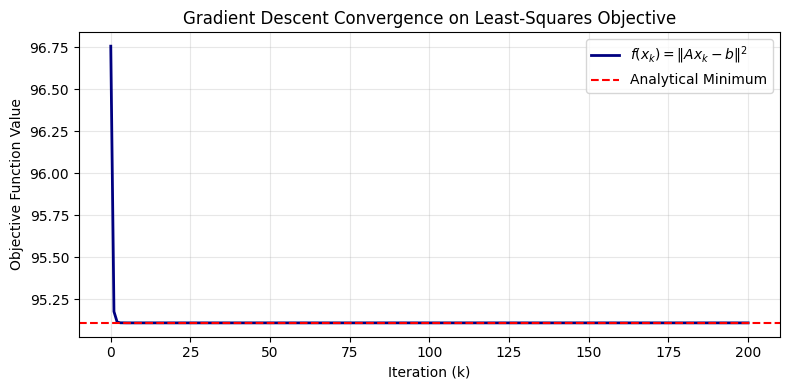

In [11]:
# Verify monotonic decrease property f(x_{k+1}) <= f(x_k)
is_monotonic = all(history_loss[i] >= history_loss[i+1] - 1e-12 for i in range(len(history_loss)-1))
print(f"Is objective function value monotonically non-increasing? {is_monotonic}")

# Plot convergence history
plt.figure(figsize=(8, 4))
plt.plot(history_loss, linewidth=2, color='navy', label=r'$f(x_k) = \|Ax_k - b\|^2$')
plt.axhline(y=ls_objective(x_analytical), color='red', linestyle='--', label='Analytical Minimum')
plt.xlabel('Iteration (k)')
plt.ylabel('Objective Function Value')
plt.title('Gradient Descent Convergence on Least-Squares Objective')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

We plot the convergence curve to visually verify that gradient descent monotonically decreases the objective function value across iterations. It's mathematically verified and demonstrated in the graph.

# Checklist


*   Read, checked, and personalized each example. Also extended at least one example. They run without errors.
*   Covered key concepts from the textbook and illustrated them in python.
*   Explanations written in my own words accompany each example.
*   Saved directly from collab to github.
*   Carefully formatted, code is explained in comments, and it follows the given order from the textbook and in the canvas assignment